# Exercise 4

# 4.1

In [3]:
import autograd.numpy as np
import pandas as pd

In [4]:
# load in dataset
df = pd.read_csv('credit_dataset.csv', header=None)
X = df.iloc[:-1, :].values
y = df.iloc[-1, :].values

In [5]:
# standard normalization function - with nan checker / filler in-er
def standard_normalizer(x):    
    # compute the mean and standard deviation of the input
    x_means = np.nanmean(x,axis = 1)[:,np.newaxis]
    x_stds = np.nanstd(x,axis = 1)[:,np.newaxis]   

    # check to make sure that x_stds > small threshold, for those not
    # divide by 1 instead of original standard deviation
    ind = np.argwhere(x_stds < 10**(-2))
    if len(ind) > 0:
        ind = [v[0] for v in ind] # Just keep the row index
        adjust = np.zeros((x_stds.shape))
        adjust[ind] = 1.0
        x_stds += adjust

    # fill in any nan values with means 
    ind = np.argwhere(np.isnan(x) == True)
    for i in ind:
        x[i[0],i[1]] = x_means[i[0]]

    # create standard normalizer function
    normalizer = lambda data: (data - x_means)/x_stds

    # create inverse standard normalizer
    inverse_normalizer = lambda data: data*x_stds + x_means

    # return normalizer 
    return normalizer,inverse_normalizer

In [6]:
normalizer,inverse_normalizer = standard_normalizer(X)
X_norm, X_inverse_norm = normalizer(X), inverse_normalizer(normalizer(X))

# 4.2

In [7]:
# compute linear combination of input points
def model(x,w):
    a = w[0] + np.dot(x.T,w[1:])
    return a.T

# an implementation of the perceptron cost
def perceptron(w):
    cost = np.sum(np.maximum(0, -y*model(X_norm, w)))
    return cost/float(np.size(y))
    

In [8]:

from autograd import grad
# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return weight_history, cost_history

In [9]:
# parameters for gradient descent
max_its = 1000
N = X_norm.shape[0]  # number of features (rows) in X_norm
w = 0.1*np.random.randn(N+1)  # bias + weights for each feature
alpha = 0.1
weight_history, cost_history = gradient_descent(perceptron,alpha,max_its,w)

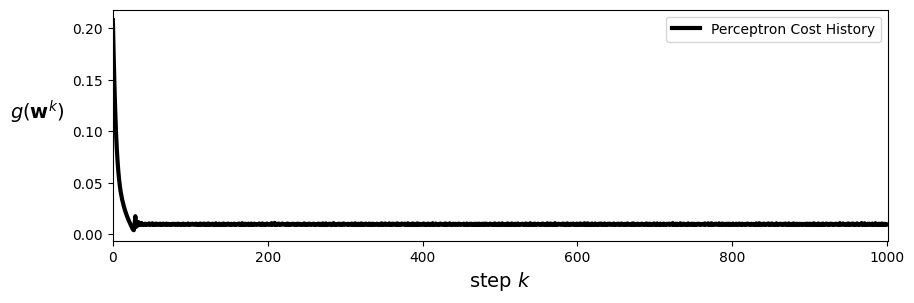

In [10]:
# plot cost function history
from MLRPlotting import static_plotter
# plotting the cost histories

# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history],start=0,points=False,labels=[r'Perceptron Cost History'])

In [11]:
### miscounts ###
def miscount(w, x, y):
    preds = model(x, w)
    return np.sum((y*preds)<0)
miscount_history = [miscount(v,X_norm,y) for v in weight_history]

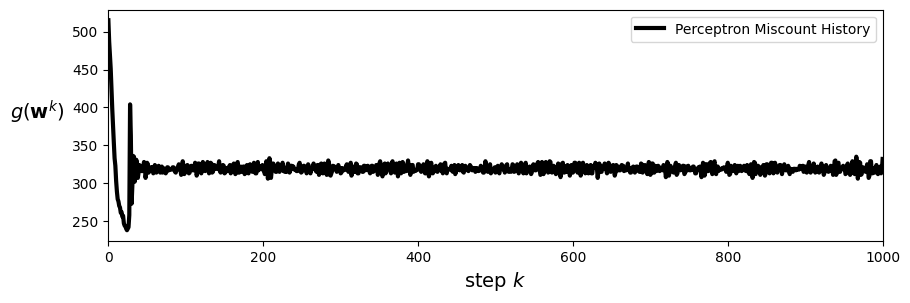

In [12]:
# plotting the miscount history
static_plotter.plot_cost_histories([miscount_history],start=0,points=False,labels=[r'Perceptron Miscount History'])

In [13]:
# accuracy
accuracy = (len(X_norm[0]) - miscount_history[-1]) / 10
print(f'Perceptron Accuracy: {accuracy:.2f}%')

Perceptron Accuracy: 66.80%


The best accuracy we have been able to achieve with the perceptron is 68.50%. We levraged many values of alpha and even normalized gradients, but we were not able to achieve an accuracy higher than this. This is likely due to the fact that the perceptron is a linear classifier, and the data may not be linearly separable.

# 4.3

In [14]:
# confusion matrix
w_opt = weight_history[-1]  # optimall weights after gradient descent
TP = np.sum((y == 1) & (model(X_norm, w_opt) > 0))
TN = np.sum((y == -1) & (model(X_norm, w_opt) <= 0))
FP = np.sum((y == -1) & (model(X_norm, w_opt) > 0))
FN = np.sum((y == 1) & (model(X_norm, w_opt) <= 0))

# display
print("Confusion Matrix:")
print("            Pred +1    Pred -1")
print(f"True +1     {TP:8d}    {FN:8d}")
print(f"True -1     {FP:8d}    {TN:8d}")

Confusion Matrix:
            Pred +1    Pred -1
True +1          524         176
True -1          156         144
